In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import pathlib
import numpy as np

%matplotlib widget

data_path = pathlib.Path('./hw_util_bm.csv')
max_path = pathlib.Path('./hw_util_max_values.csv')

Text(0, 0.5, 'Normalized utilization [%]')

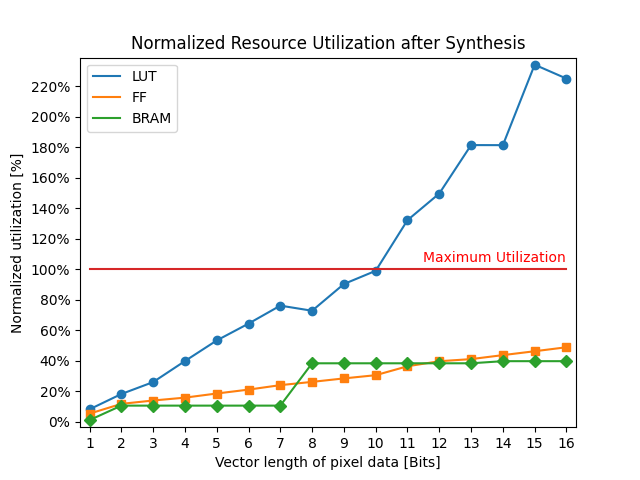

In [125]:
df = pd.read_csv(data_path)
df = df.set_index('bits')
max = pd.read_csv(max_path)
max = max.set_index('Key')
for (index, rows) in max.iterrows():
    df[index] = df[index] / rows['Max']
ax = df[['LUT_synth', 'FF_synth', 'BRAM']].plot.line()
ax.legend(['LUT', 'FF', 'BRAM'])
markers = ['o', 's', 'D']
for i, line in enumerate(ax.get_lines()):
    line.set_marker(markers[i])
ax.plot(np.arange(1,17,1), np.ones(16))
ax.set_xticks(range(1, 17))
ax.set_yticks(np.arange(0, 2.5, 0.2))
ax.set_yticklabels(['{:,.0%}'.format(x) for x in ax.get_yticks()])
ax.margins(x=.02,y=.02)
ax.text(11.5, 1.12, 'Maximum Utilization', ha='left', va='top', fontsize=10, color='red')
ax.set_title("Normalized Resource Utilization after Synthesis")
ax.set_xlabel('Vector length of pixel data [Bits]')
ax.set_ylabel('Normalized utilization [%]')
